In [1]:
DAY_DIR = "2026_06_04"
DS_DIR = "208735" # 208735 159090 73131


In [2]:
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

import utils

In [3]:
RQ = "RQ2"
ROOT = Path("..")

In [4]:
df_config = pd.read_csv(os.path.join(ROOT,'dataset_config.csv'),dtype=str)
cs = df_config[df_config['data_subdir']==DS_DIR]['original_gsms'].values[0]

In [5]:

BASE = ROOT / DAY_DIR / DS_DIR

OUT_DIR = "ImgOut" 
OUT = ROOT / OUT_DIR / DAY_DIR /  RQ / DS_DIR
OUT.mkdir(parents=True, exist_ok=True)
OUT_CSV = OUT / "CSV"
OUT_CSV.mkdir(parents=True, exist_ok=True)
OUT_PDF = OUT / "PDF"
OUT_PDF.mkdir(parents=True, exist_ok=True)
OUT_PNG = OUT / "PNG"
OUT_PNG.mkdir(parents=True, exist_ok=True)
INPUT = OUT / "INPUT"

sns.set_theme(style="whitegrid", font_scale=0.9)

In [6]:
# -----------------------------
# Locate folder
# -----------------------------
dict_dea = {}
dict_wgcna = {}
for el in sorted(os.listdir(BASE)):
    folder = os.path.join(BASE, el)
    try:
        dea_files, wgcna_files = utils.read_files(folder)
        match = re.search(r'k(\d+)', folder)
        value = int(match.group(1))
    except:
        print(folder)
        continue
    # -----------------------------
    # Read sets
    # -----------------------------
    dea_labels = [str(utils.dea_thr(f)) for f in dea_files]  # e.g. 50, 60, ... 150
    dea_labels = [str(int(x)/100) for x in dea_labels]
    wgcna_labels = [f"{a}_{b}" for (a, b) in map(utils.wgcna_thr, wgcna_files)]  # e.g. 60_60, 65_65, ...
    wgcna_labels = [f'{int(x[:2])/100:.2f}' for x in wgcna_labels]
    

    if value == 0:
        ref_dea_sets = [utils.read_gene_set(os.path.join(folder, f)) for f in dea_files]
        ref_wgcna_sets = [utils.read_gene_set(os.path.join(folder, f)) for f in wgcna_files]
        continue
 
    dea_sets = [utils.read_gene_set(os.path.join(folder, f)) for f in dea_files]
    wgcna_sets = [utils.read_gene_set(os.path.join(folder, f)) for f in wgcna_files]
        
    # -----------------------------
    # Compute Jaccard matrices
    # -----------------------------
    j_wcgna = {z:utils.jaccard(x,y) for x, y, z in zip(wgcna_sets, ref_wgcna_sets, wgcna_labels)}
    j_dea = {z:utils.jaccard(x,y) for x, y, z in zip(dea_sets, ref_dea_sets, dea_labels)}
    
    
    if value not in dict_dea:
        dict_dea[value] = [j_dea]
    else:
        dict_dea[value].append(j_dea)

    if value not in dict_wgcna:
        dict_wgcna[value] = [j_wcgna]
    else:
        dict_wgcna[value].append(j_wcgna)
    

../2026_06_04/208735/.DS_Store


In [7]:
def make_k_label(k, total_len):
    remaining = total_len - 2 * k
    return f"{k} ({remaining} / {total_len})"

In [8]:


def plot_isf(data, param_name, inner_params, approach):
    rows = []
    for outer_param, list_of_dicts in data.items():
        for rep_idx, d in enumerate(list_of_dicts):
            for inner_param, value in d.items():
                rows.append({
                    "outer_param": outer_param,
                    "replicate": rep_idx,
                    "inner_param": inner_param,
                    "value": value})
    
    df = pd.DataFrame(rows)
    df["inner_param"] = pd.Categorical(df["inner_param"], categories=inner_params, ordered=True)
    summary = (df.groupby(["outer_param", "inner_param"], as_index=False, observed=False).agg(mean_value=("value", "mean"), std_value=("value", "std")))
    summary["lower"] = summary["mean_value"] - summary["std_value"]
    summary["upper"] = summary["mean_value"] + summary["std_value"]
    total_len = len(cs)
    summary["k_label"] = summary["outer_param"].apply(
        lambda k: make_k_label(k, total_len)
    )
    plt.figure(figsize=(7, 3.5))
    palette = sns.color_palette("viridis", n_colors=len(inner_params))
    for color, inner in zip(palette, inner_params):
        sub = summary[summary["inner_param"] == inner].sort_values("outer_param")
        sns.lineplot(data=sub, x="outer_param", y="mean_value", label=inner, color=color, marker="o")
        plt.fill_between(sub["outer_param"], sub["lower"], sub["upper"], color=color, alpha=0.05)
    plt.ylim((0,1))
    plt.xlabel("K -- (Retained / Original)")
    plt.ylabel("Jaccard similarity w.r.t. original dataset")
    plt.legend(title=param_name, bbox_to_anchor=(1.02, 1), loc="upper left")
    k_values = sorted(summary["outer_param"].unique())
    k_labels = [make_k_label(k, total_len) for k in k_values]
    plt.xticks(k_values, k_labels)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PNG,f'{RQ}_{DS_DIR}_{approach}_isf.png'), format='png', dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(OUT_PDF,f'{RQ}_{DS_DIR}_{approach}_isf.pdf'), format='pdf', bbox_inches='tight')
    plt.show()


In [9]:
from matplotlib.lines import Line2D


def _get_param_palette(approach, palette_name="viridis"):
    print(approach)
    if approach.upper() == 'DEA':
        n = 11
    elif approach.upper() == 'WGCNA':
        n = 8
    return sns.color_palette(palette_name, n_colors=n)


def plot_isf(data, param_name, inner_params, approach):
    rows = []
    for outer_param, list_of_dicts in data.items():
        for rep_idx, d in enumerate(list_of_dicts):
            for inner_param, value in d.items():
                rows.append({
                    "outer_param": outer_param,
                    "replicate": rep_idx,
                    "inner_param": inner_param,
                    "value": value
                })
    
    df = pd.DataFrame(rows)
    df["inner_param"] = pd.Categorical(
        df["inner_param"], 
        categories=inner_params, 
        ordered=True
    )

    summary = (
        df.groupby(["outer_param", "inner_param"], as_index=False, observed=False)
          .agg(mean_value=("value", "mean"), std_value=("value", "std"))
    )

    summary["lower"] = summary["mean_value"] - summary["std_value"]
    summary["upper"] = summary["mean_value"] + summary["std_value"]

    total_len = len(cs)
    summary["k_label"] = summary["outer_param"].apply(
        lambda k: make_k_label(k, total_len)
    )

    fig, ax = plt.subplots(figsize=(7.5, 4.2))

    palette = _get_param_palette(approach, palette_name="viridis")

    for color, inner in zip(palette, inner_params):
        sub = summary[summary["inner_param"] == inner].sort_values("outer_param")

        sns.lineplot(
            data=sub,
            x="outer_param",
            y="mean_value",
            color=color,
            marker="o",
            linewidth=2,
            markersize=6,
            ax=ax,
            legend=False
        )

        ax.fill_between(
            sub["outer_param"],
            sub["lower"],
            sub["upper"],
            color=color,
            alpha=0.05
        )

    ax.set_ylim((0, 1))
    ax.set_xlabel(
        r"Subsampling level $k$ (retained samples $N_k/N$)",
        fontsize=20,
        labelpad=8
    )
    ax.set_ylabel(
        r"$J(G_{0}, G_{k})$",
        fontsize=20,
        labelpad=8
    )

    k_values = sorted(summary["outer_param"].unique())
    k_labels = [make_k_label(k, total_len) for k in k_values]
    ax.set_xticks(k_values)
    ax.set_xticklabels(k_labels, fontsize=18)

    ax.tick_params(axis="y", labelsize=16)
    ax.tick_params(axis="x", labelsize=16)

    plt.tight_layout()

    fig.savefig(
        os.path.join(OUT_PNG, f'{RQ}_{DS_DIR}_{approach}_isf.png'),
        format='png',
        dpi=300,
        bbox_inches='tight'
    )

    fig.savefig(
        os.path.join(OUT_PDF, f'{RQ}_{DS_DIR}_{approach}_isf.pdf'),
        format='pdf',
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

In [10]:
def save_isf_legend(param_name, inner_params, filename_prefix="isf_legend"):
    palette = sns.color_palette("viridis", n_colors=len(inner_params))

    handles = [
        Line2D(
            [0], [0],
            color=color,
            marker="o",
            linewidth=2,
            label=str(inner)
        )
        for color, inner in zip(palette, inner_params)
    ]

    fig, ax = plt.subplots(figsize=(max(4, len(inner_params) * 0.8), 0.6))
    ax.axis("off")

    legend = ax.legend(
        handles=handles,
        title=param_name,
        loc="center",
        ncol=len(inner_params),
        frameon=False,
        handlelength=1.8,
        columnspacing=1.2
    )

    plt.tight_layout()

    fig.savefig(
        os.path.join(OUT_PNG, f"{RQ}_{DS_DIR}_{filename_prefix}.png"),
        format="png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.02
    )

    fig.savefig(
        os.path.join(OUT_PDF, f"{RQ}_{DS_DIR}_{filename_prefix}.pdf"),
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.02
    )

    plt.show()
    plt.close(fig)

dea


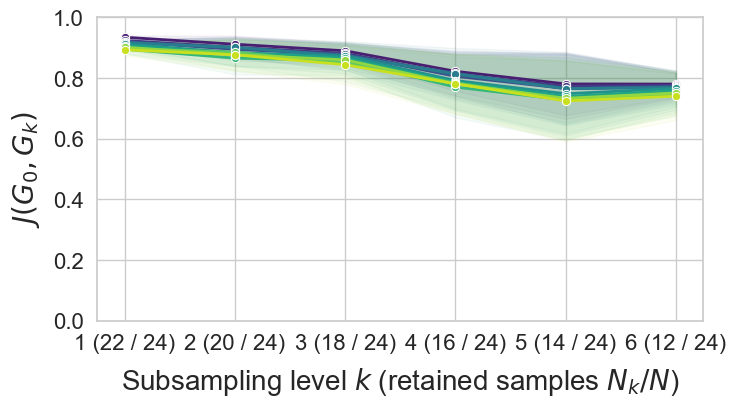

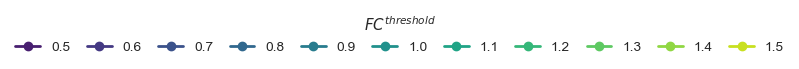

wgcna


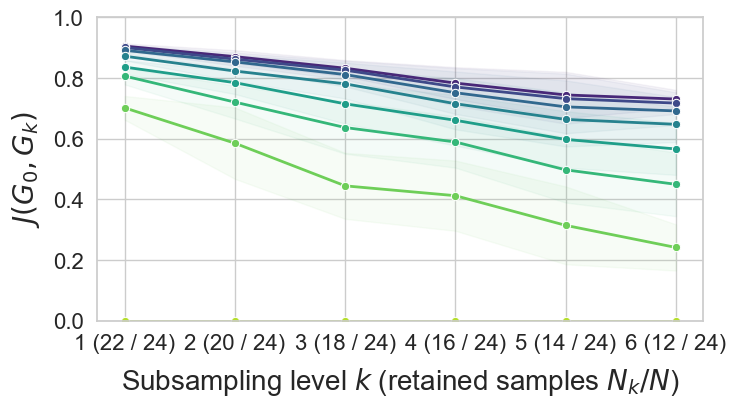

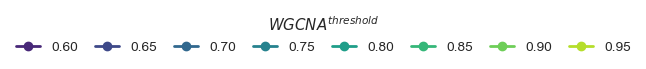

In [11]:
plot_isf(dict_dea, utils.APPROACH_SPECS['DEA']["param_name"], utils.APPROACH_SPECS['DEA']["param"], 'dea')
save_isf_legend(utils.APPROACH_SPECS['DEA']["param_name"], utils.APPROACH_SPECS['DEA']["param"], filename_prefix=f"dea_isf_legend")

plot_isf(dict_wgcna, utils.APPROACH_SPECS['WGCNA']["param_name"], utils.APPROACH_SPECS['WGCNA']["param"], 'wgcna')
save_isf_legend(utils.APPROACH_SPECS['WGCNA']["param_name"], utils.APPROACH_SPECS['WGCNA']["param"], filename_prefix=f"wgcna_isf_legend")


# GOntoSim


In [12]:
INPUT_DIR = ROOT / "ImgOut" / DAY_DIR / RQ / DS_DIR / "INPUT"

In [13]:
summary = pd.read_csv(INPUT_DIR / f"{RQ}_{DS_DIR}_gontosim_summary.csv", dtype={"param": str})
summary.head()

,dataset,approach,go_category,k,param,mean_similarity,std_similarity,n_runs,mean_terms_current,mean_terms_reference
0,208735,DEA,BP,1,100,0.9507,0.010001,10,209.2,225.0
1,208735,DEA,BP,1,110,0.9509,0.008672,10,181.0,173.0
2,208735,DEA,BP,1,120,0.9507,0.005755,10,159.7,169.0
3,208735,DEA,BP,1,130,0.9598,0.013669,10,143.3,145.0
4,208735,DEA,BP,1,140,0.9641,0.007078,10,127.1,128.0


In [14]:
def _safe_name(x):
    return re.sub(r"[^a-zA-Z0-9_]+", "_", str(x))


def make_k_label(k, total_len):
    remaining = total_len - 2 * int(k)
    return f"{int(k)} ({remaining}/{total_len})"

def plot_isf_GO(summary_df, approach, param_name, inner_params, go_category):
    data = summary_df[
        (summary_df["approach"] == approach) & 
        (summary_df["go_category"] == go_category)
    ].copy()

    if data.empty:
        print(f"No GOntoSim values for {param_name} - {go_category}")
        return data

    data["param"] = pd.Categorical(
        data["param"], 
        categories=inner_params, 
        ordered=True
    )

    data["lower"] = data["mean_similarity"] - data["std_similarity"].fillna(0)
    data["upper"] = data["mean_similarity"] + data["std_similarity"].fillna(0)

    total_len = len(cs)

    fig, ax = plt.subplots(figsize=(7.5, 4.2))

    palette = _get_param_palette(approach, palette_name="viridis")

    for color, inner in zip(palette, inner_params):
        sub = data[data["param"] == inner].sort_values("k")
        sub = sub.dropna(subset=["mean_similarity"])

        if sub.empty:
            continue

        sns.lineplot(
            data=sub,
            x="k",
            y="mean_similarity",
            color=color,
            marker="o",
            linewidth=2,
            markersize=6,
            ax=ax,
            legend=False
        )

        ax.fill_between(
            sub["k"],
            sub["lower"],
            sub["upper"],
            color=color,
            alpha=0.06
        )

    ax.set_ylim((0, 1.05))

    ax.set_xlabel(
        r"Subsampling level $k$ (retained samples $N_k/N$)",
        fontsize=20,
        labelpad=8
    )

    ax.set_ylabel(
        rf"$GOntoSim(T_0, T_k)$",
        fontsize=20,
        labelpad=8
    )

    k_values = sorted(data["k"].dropna().unique())
    k_labels = [make_k_label(k, total_len) for k in k_values]

    ax.set_xticks(k_values)
    ax.set_xticklabels(k_labels, fontsize=18)

    ax.tick_params(axis="y", labelsize=16)
    ax.tick_params(axis="x", labelsize=16)

    ax.grid(True, alpha=0.3)

    plt.tight_layout()

    safe_category = _safe_name(go_category.lower())
    safe_param = _safe_name(param_name)
    safe_approach = _safe_name(approach)

    fig.savefig(
        OUT_PNG / f"{RQ}_{DS_DIR}_{safe_approach}_{safe_category}_{safe_param}_gontosim.png",
        format="png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        OUT_PDF / f"{RQ}_{DS_DIR}_{safe_approach}_{safe_category}_{safe_param}_gontosim.pdf",
        format="pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return data

def save_isf_GO_legend(param_name, inner_params, approach=None, filename_prefix="gontosim_legend"):
    palette = _get_param_palette(approach, palette_name="viridis")

    handles = [
        Line2D(
            [0], [0],
            color=color,
            marker="o",
            linewidth=2,
            markersize=6,
            label=str(inner)
        )
        for color, inner in zip(palette, inner_params)
    ]

    n_items = len(inner_params)
    ncol = n_items

    fig_width = max(5.5, ncol * 1.05)
    fig_height = 0.8 if n_items <= 6 else 1.15

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    ax.legend(
        handles=handles,
        title=param_name,
        loc="center",
        ncol=ncol,
        frameon=False,
        fontsize=11,
        title_fontsize=12,
        handlelength=1.8,
        columnspacing=1.2,
        handletextpad=0.5
    )

    plt.tight_layout()

    safe_prefix = _safe_name(filename_prefix)
    safe_param = _safe_name(param_name)

    if approach is not None:
        safe_approach = _safe_name(approach)
        filename = f"{safe_prefix}_{safe_approach}_{safe_param}"
    else:
        filename = f"{safe_prefix}_{safe_param}"

    fig.savefig(
        OUT_PNG / f"{RQ}_{DS_DIR}_{safe_approach}_{safe_param}_legend.png",
        format="png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.02
    )

    fig.savefig(
        OUT_PDF / f"{RQ}_{DS_DIR}_{safe_approach}_{safe_param}_legend.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.02
    )

    plt.show()
    plt.close(fig)

DEA


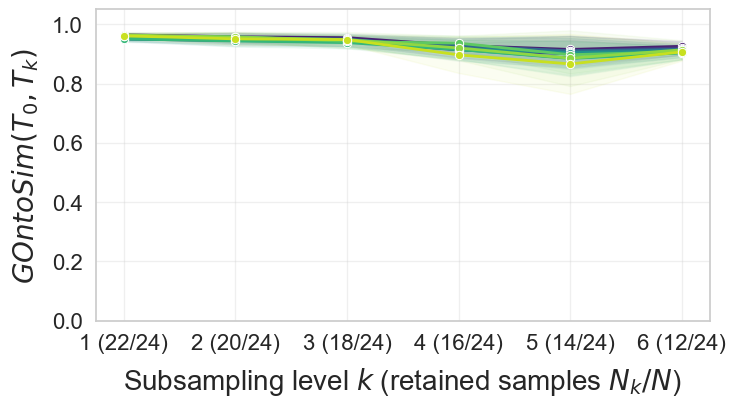

DEA


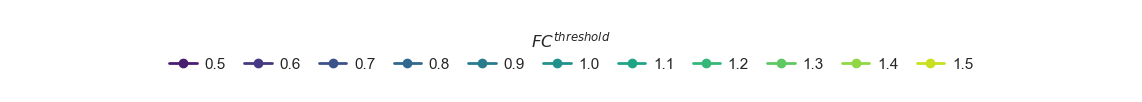

DEA


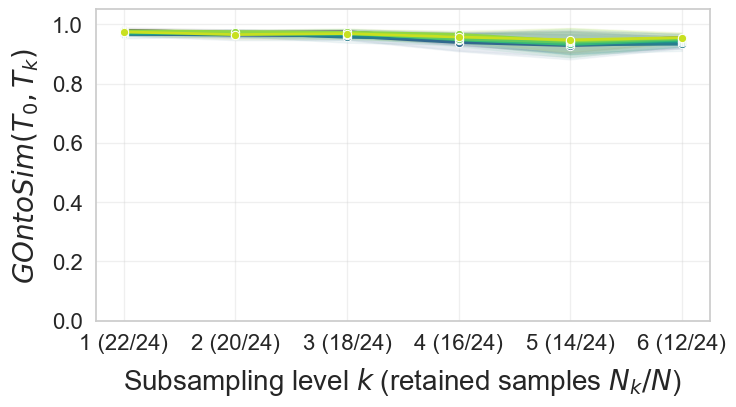

DEA


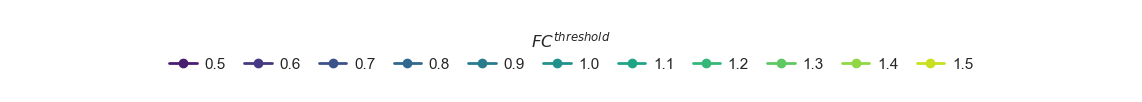

DEA


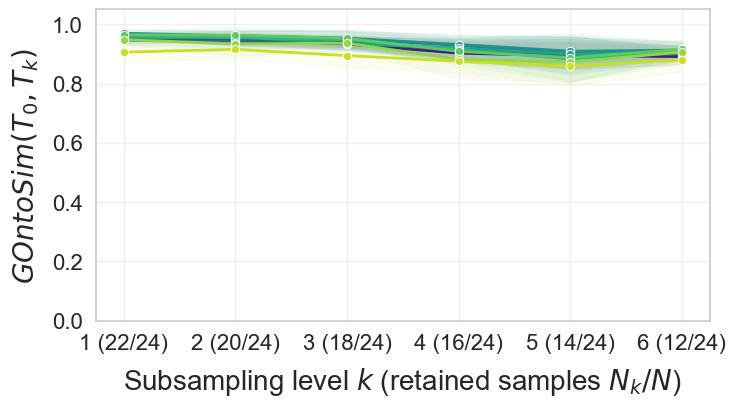

DEA


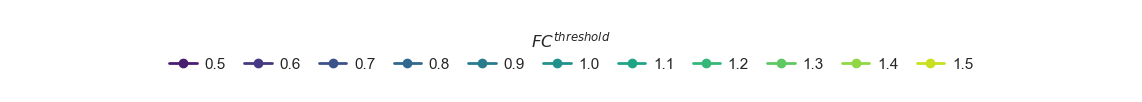

WGCNA


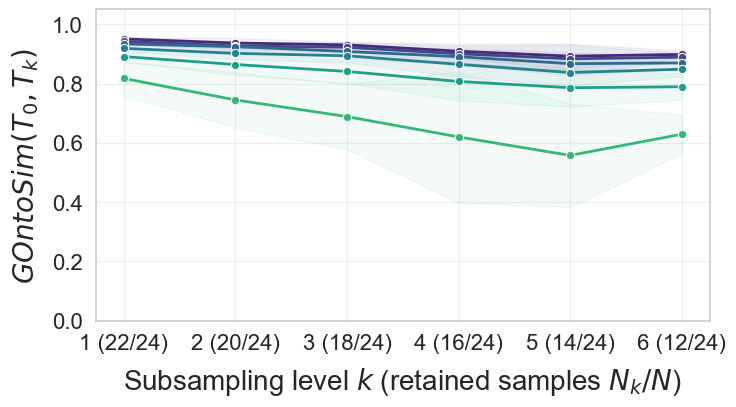

WGCNA


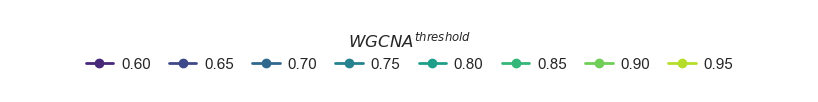

WGCNA


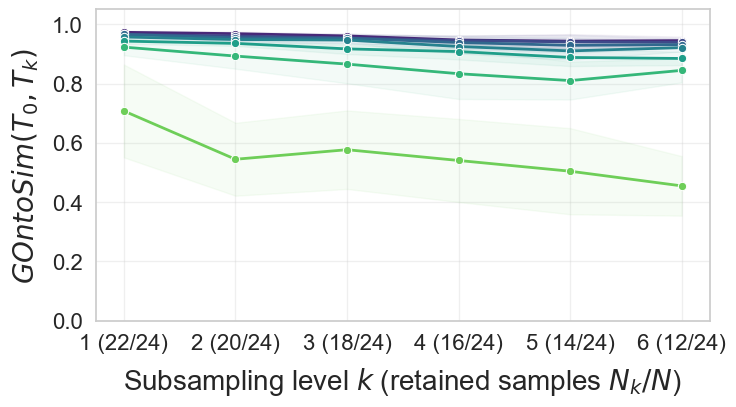

WGCNA


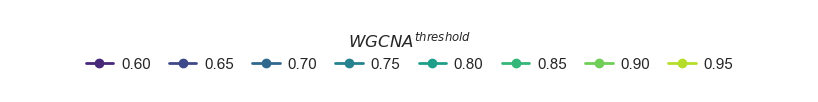

WGCNA


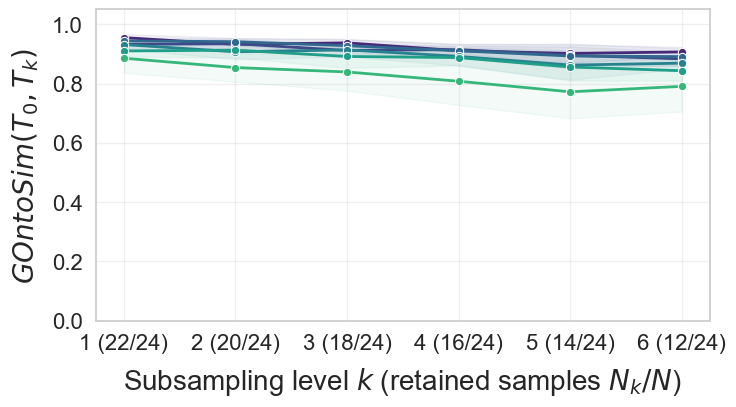

WGCNA


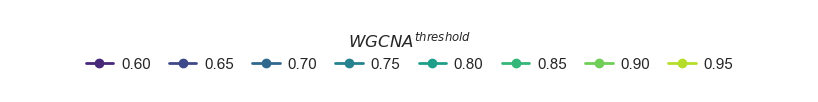

In [15]:
plot_data = {}
for approach, spec in utils.APPROACH_SPECS.items():
    approach_summary = summary[summary["approach"] == approach]
    inner_params = sorted(approach_summary["param"].dropna().unique(), key=spec["sort_key"])

    plot_data[approach] = {}
    for go_category in utils.GO_CATEGORIES:
        plot_data[approach][go_category] = plot_isf_GO(summary, approach, spec["param_name"], inner_params, go_category)
        save_isf_GO_legend(spec["param_name"], spec["param"], approach=approach)